# 01 Â· Profiling the PriceCatcher data

Goal: understand the raw data **before** cleaning it. Every query runs in DuckDB directly on the
parquet files in `data/raw/` (about 47 million rows), and only small results come back into pandas.

Sections: 1) date coverage Â· 2) shops per type and state Â· 3) items per category Â·
4) price distributions and outliers Â· 5) what the cleaning step must handle.

Run `src/download.py` first. The cleaned table used in section 4 comes from `src/build.py`.

In [1]:
from pathlib import Path
import duckdb
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = (ROOT / "data" / "raw").as_posix()
STAGING = (ROOT / "data" / "staging").as_posix()

con = duckdb.connect()
con.execute(f"CREATE VIEW prices  AS SELECT * FROM read_parquet('{RAW}/pricecatcher_*.parquet')")
con.execute(f"CREATE VIEW items   AS SELECT * FROM read_parquet('{RAW}/lookup_item.parquet')")
con.execute(f"CREATE VIEW premises AS SELECT * FROM read_parquet('{RAW}/lookup_premise.parquet')")
sql = lambda q: con.execute(q).df()   # helper: run SQL, get a small pandas table
plt.rcParams.update({"figure.figsize": (10, 3.5), "axes.spines.top": False, "axes.spines.right": False})
sql("SELECT COUNT(*) AS rows, MIN(date) AS first_day, MAX(date) AS last_day FROM prices")

,rows,first_day,last_day
0,47365287,2024-12-01,2026-11-24


## 1. Date coverage
How many prices per month, and how many days in each month actually have data?

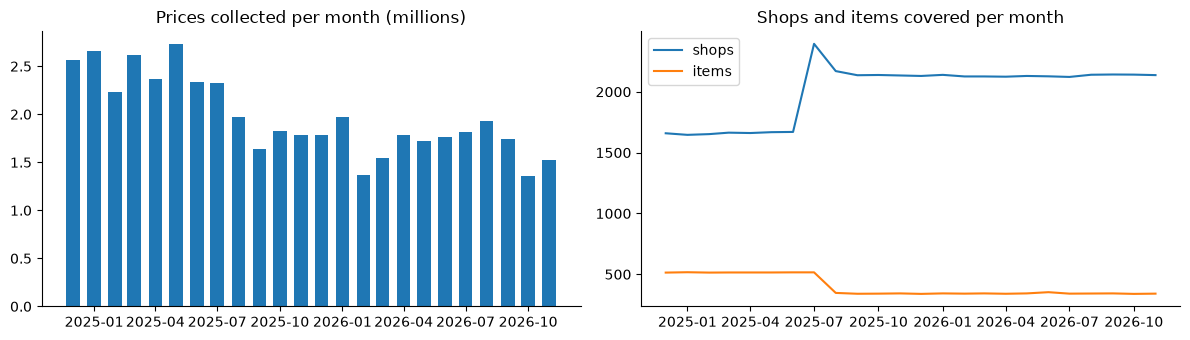

,month,rows,days_with_data,shops,items
0,2024-12-01,2567516,30,1659,514
1,2025-01-01,2662849,29,1646,517
2,2025-02-01,2229658,26,1652,514
3,2025-03-01,2615276,30,1664,515
4,2025-04-01,2367027,28,1661,515
5,2025-05-01,2727012,29,1668,515
6,2025-06-01,2333848,27,1670,516
7,2025-07-01,2323499,30,2394,516
8,2025-08-01,1976201,31,2170,347
9,2025-09-01,1643623,28,2136,340


In [2]:
monthly = sql('''
    SELECT date_trunc('month', date) AS month, COUNT(*) AS rows,
           COUNT(DISTINCT date) AS days_with_data,
           COUNT(DISTINCT premise_code) AS shops, COUNT(DISTINCT item_code) AS items
    FROM prices GROUP BY 1 ORDER BY 1''')
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].bar(monthly.month, monthly.rows / 1e6, width=20); ax[0].set_title("Prices collected per month (millions)")
ax[1].plot(monthly.month, monthly.shops, label="shops"); ax[1].plot(monthly.month, monthly["items"], label="items")
ax[1].set_title("Shops and items covered per month"); ax[1].legend(); plt.tight_layout(); plt.show()
monthly

**Takeaways**
- Volume fell from ~2.6M prices a month in early 2025 to ~1.4â€“1.9M in 2026.
- The survey changed shape in mid-2025: shops jumped in July 2025 and the item list shrank in August 2025.
  Trends must compare like with like across that break.
- Several months are missing days (e.g. October 2026 starts on the 10th), so weekly figures need observation counts.

## 2. Shops per type and state
The premise lookup lists every shop ever surveyed; the price files show which are active.

In [3]:
shops = sql('''
    SELECT '[' || premise_type || ']' AS premise_type_raw, COUNT(*) AS in_lookup,
           COUNT(*) FILTER (WHERE premise_code IN (SELECT DISTINCT premise_code FROM prices)) AS active
    FROM premises GROUP BY 1 ORDER BY 2 DESC''')
shops   # brackets show hidden spaces: note 'Pasar Basah ' vs 'Pasar Basah'

,premise_type_raw,in_lookup,active
0,[Pasar Mini],926,814
1,[Pasar Raya / Supermarket],888,820
2,[Kedai Runcit],623,496
3,[Pasar Basah ],338,300
4,[Restoran Melayu],297,0
5,[Restoran India Muslim],223,0
6,[Restoran Cina],196,0
7,[Hypermarket],181,164
8,[Medan Selera],126,0
9,[Foodcourt],94,0


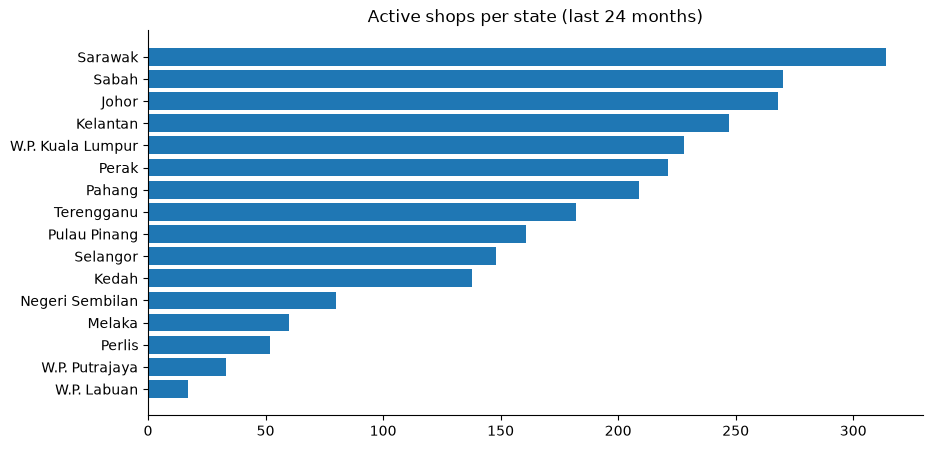

In [4]:
by_state = sql('''
    SELECT p.state, COUNT(DISTINCT f.premise_code) AS active_shops, COUNT(*) AS prices
    FROM prices f JOIN premises p USING (premise_code) GROUP BY 1 ORDER BY 2''')
plt.barh(by_state.state, by_state.active_shops); plt.title("Active shops per state (last 24 months)")
plt.gcf().set_size_inches(10, 5); plt.show()

**Takeaways**
- One placeholder shop (code `-1`, "Unknown Premise", no state) must be dropped.
- `Pasar Basah ` has a trailing space on most rows, so it would split into two groups if not trimmed.
- Restaurants and food courts exist in the lookup but have **no prices** in the last 24 months:
  the cooked-food survey is not in the recent data. Active types are supermarkets, wet markets,
  hypermarkets, minimarts, sundry shops and a few wholesalers (Borong).

## 3. Items per category

In [5]:
cats = sql('''
    SELECT i.item_group, COUNT(DISTINCT f.item_code) AS items_with_prices, COUNT(*) AS prices
    FROM prices f JOIN items i USING (item_code) GROUP BY 1 ORDER BY 3 DESC''')
cats

,item_group,items_with_prices,prices
0,BARANGAN SEGAR,162,28306241
1,BARANGAN BERBUNGKUS,205,9105702
2,BARANGAN KERING,27,5515076
3,SUSU DAN BARANGAN BAYI,34,1839460
4,MINUMAN,43,888520
5,PRODUK KEBERSIHAN,36,813617


In [6]:
sql('''
    SELECT COUNT(DISTINCT item_code) AS unknown_codes, COUNT(*) AS rows,
           ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM prices), 2) AS pct_of_all
    FROM prices ANTI JOIN items USING (item_code)''')

,unknown_codes,rows,pct_of_all
0,41,896671,1.89


**Takeaways**
- Fresh produce (BARANGAN SEGAR: chicken, fish, vegetables, eggs) is ~60% of all prices.
- 41 item codes (~1.9% of rows) are **not in the item lookup**, so we can't name them. They're
  kept but flagged `item_known = false` and left out of named-item analysis.

## 4. Price distributions and outliers
Raw prices range from RM 0.01 to RM 8,245. What do the extremes look like?

In [7]:
sql('''
    SELECT f.date, f.price, i.item, i.unit
    FROM prices f JOIN items i USING (item_code) ORDER BY price DESC LIMIT 8''')

,date,price,item,unit
0,2025-04-28,8245.0,S-26 SMA RUMUSAN BAYI LANGKAH 1 - (KOTAK) (550g),550 g
1,2026-04-27,7985.0,S-26 SMA RUMUSAN BAYI LANGKAH 1 - (KOTAK) (550g),550 g
2,2026-06-22,7090.0,NAN LANGKAH 1 RUMUSAN BAYI (KOTAK),600 g
3,2025-12-22,6629.0,NAN LANGKAH 2 RUMUSAN SUSULAN (KOTAK),600 g
4,2025-06-30,6490.0,S-26 RUMUSAN BAYI LANGKAH 1 - (KOTAK),600 g
5,2025-06-17,6399.0,BAYAM HIJAU,1kg
6,2026-11-18,6049.0,HALIA BASAH (TUA),1kg
7,2026-05-30,5390.0,BAWANG KECIL MERAH ROSE IMPORT (INDIA),1kg


The top prices are baby formula at ~RM 8,000 when the usual price is ~RM 80: a missing decimal
point (100Ã— too high). Below is the spread of a few everyday items, then the result of the outlier
rule from `sql/01_clean.sql` (flag, never delete).

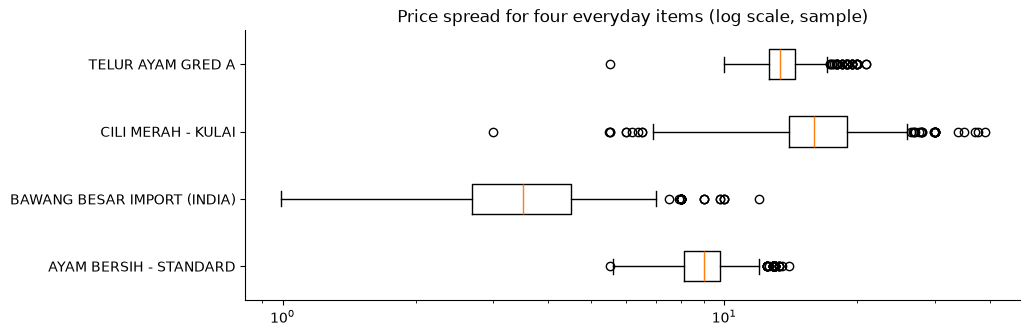

In [8]:
example = sql('''
    SELECT i.item, f.price FROM prices f JOIN items i USING (item_code)
    WHERE i.item IN ('AYAM BERSIH - STANDARD', 'TELUR AYAM GRED A', 'BAWANG BESAR IMPORT (INDIA)', 'CILI MERAH - KULAI')
    USING SAMPLE 200000 ROWS''')
fig, ax = plt.subplots()
ax.boxplot([g.price for _, g in example.groupby("item")], tick_labels=sorted(example.item.unique()), orientation='horizontal')
ax.set_xscale("log"); ax.set_title("Price spread for four everyday items (log scale, sample)"); plt.show()

In [9]:
clean = f"read_parquet('{STAGING}/prices_clean.parquet')"
sql(f'''
    SELECT COUNT(*) AS rows, SUM(is_outlier) AS flagged,
           ROUND(100 * AVG(is_outlier::INT), 2) AS pct_flagged,
           SUM(is_outlier AND price_to_median > 50) AS likely_decimal_typos
    FROM {clean}''')

,rows,flagged,pct_flagged,likely_decimal_typos
0,47365287,336323.0,0.71,276.0


In [10]:
sql(f'''
    SELECT item_group, ROUND(100 * AVG(is_outlier::INT), 2) AS pct_flagged, COUNT(*) AS rows
    FROM {clean} WHERE item_known GROUP BY 1 ORDER BY 2 DESC''')

,item_group,pct_flagged,rows
0,SUSU DAN BARANGAN BAYI,1.98,1839460
1,BARANGAN KERING,1.14,5515076
2,MINUMAN,0.99,888520
3,BARANGAN SEGAR,0.69,28306241
4,BARANGAN BERBUNGKUS,0.27,9105702
5,PRODUK KEBERSIHAN,0.20,813617


**Outlier rule:** a price is flagged when it is more than 3 Ã— *spread* away from that item's median
that month, where *spread* is the larger of the interquartile range and 10% of the median.
The 10% floor matters for price-controlled items like eggs, where most shops charge exactly the same
and the plain IQR is zero.

## 5. What the cleaning step handles (`sql/01_clean.sql`)
| Issue | Fix |
|---|---|
| Placeholder shop and item (`-1`) | dropped |
| Trailing spaces in names (`Pasar Basah `) | `trim()` every text column |
| Item codes missing from lookup (~1.9%) | kept, flagged `item_known = false` |
| Typos and unit mix-ups (e.g. 100Ã— prices) | flagged `is_outlier`, with `price_to_median` |
| East vs West Malaysia | new `region` column (Sabah, Sarawak, Labuan = East) |
| Weekly / monthly grouping | `week_start` (Monday) and `month` columns |